# 1. Modeling & Evaluation

## 1.1 Loading the Processed Dataset

This notebook uses the processed monthly sales dataset generated in the preprocessing notebook. The dataset contains monthly sales aggregated across all stores for each product family from January 2013 through July 2017.

The objective is to develop and evaluate forecasting models that predict monthly sales for the next three months.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path(
    '/content/drive/MyDrive/retail-sales-forecasting'
)
data_path = project_dir / 'data' / 'processed' / 'monthly_sales.csv'

modeling_data = pd.read_csv(
    data_path,
    parse_dates=['date']
)

modeling_data['month'] = pd.PeriodIndex(
    modeling_data['month'],
    freq='M'
)

print('Dataset shape:', modeling_data.shape)
print('Date range:', modeling_data['date'].min(),
      'to', modeling_data['date'].max())
print('Number of product families:',
      modeling_data['family'].nunique())
print('Number of months:',
      modeling_data['month'].nunique())
print('Missing values:', modeling_data.isna().sum().sum())

Dataset shape: (1815, 4)
Date range: 2013-01-01 00:00:00 to 2017-07-01 00:00:00
Number of product families: 33
Number of months: 55
Missing values: 0


In [ ]:
display(modeling_data.head())

,month,date,family,sales
0,2013-01,2013-01-01,AUTOMOTIVE,6557.0
1,2013-02,2013-02-01,AUTOMOTIVE,7220.0
2,2013-03,2013-03-01,AUTOMOTIVE,7635.0
3,2013-04,2013-04-01,AUTOMOTIVE,7485.0
4,2013-05,2013-05-01,AUTOMOTIVE,9034.0


In [ ]:
print('Column names:', modeling_data.columns.tolist())
print('\nData types:')
print(modeling_data.dtypes)

print('\nFirst 5 rows:')
display(modeling_data.head().to_string(index=False))

Column names: ['month', 'date', 'family', 'sales']

Data types:
month          period[M]
date      datetime64[ns]
family            object
sales            float64
dtype: object

First 5 rows:


'  month       date     family  sales\n2013-01 2013-01-01 AUTOMOTIVE 6557.0\n2013-02 2013-02-01 AUTOMOTIVE 7220.0\n2013-03 2013-03-01 AUTOMOTIVE 7635.0\n2013-04 2013-04-01 AUTOMOTIVE 7485.0\n2013-05 2013-05-01 AUTOMOTIVE 9034.0'

# 2. Feature Engineering


## 2.1 Creating Time-Based and Historical Features

Feature engineering transforms the monthly sales dataset into a format suitable for machine learning. Calendar features represent the timing of each observation, while lag features and rolling statistics capture historical sales patterns.

All historical features are calculated separately for each product family and use only information available before the month being predicted. This helps prevent data leakage.

In [ ]:
# Create a copy of the processed dataset
feature_data = modeling_data.copy()

In [ ]:
feature_data = feature_data.sort_values(
    ['family', 'date']
).reset_index(drop=True)

feature_data['month_number'] = feature_data['date'].dt.month

feature_data['time_index'] = (
    (feature_data['date'].dt.year - 2013) * 12
    + feature_data['date'].dt.month
)

display(
    feature_data[
        ['date', 'family', 'sales', 'month_number', 'time_index']
    ].head(10)
)

,date,family,sales,month_number,time_index
0,2013-01-01,AUTOMOTIVE,6557.0,1,1
1,2013-02-01,AUTOMOTIVE,7220.0,2,2
2,2013-03-01,AUTOMOTIVE,7635.0,3,3
3,2013-04-01,AUTOMOTIVE,7485.0,4,4
4,2013-05-01,AUTOMOTIVE,9034.0,5,5
5,2013-06-01,AUTOMOTIVE,8311.0,6,6
6,2013-07-01,AUTOMOTIVE,8508.0,7,7
7,2013-08-01,AUTOMOTIVE,8164.0,8,8
8,2013-09-01,AUTOMOTIVE,7029.0,9,9
9,2013-10-01,AUTOMOTIVE,6803.0,10,10


## 2.2 Creating Lag Features

Lag features represent historical sales from previous months. They allow the model to learn from recent sales patterns and recurring annual patterns.

The lag features used in this project are `lag_1`, `lag_2`, `lag_3`, and `lag_12`. They are calculated separately for each product family to ensure that historical sales from different families are not mixed.

In [ ]:
for lag in [1, 2, 3, 12]:
    feature_data[f'lag_{lag}'] = (
        feature_data.groupby('family')['sales'].shift(lag)
    )

display(
    feature_data.loc[
        feature_data['family'] == 'AUTOMOTIVE',
        ['date', 'family', 'sales', 'lag_1', 'lag_2', 'lag_3', 'lag_12']
    ].head(16)
)

,date,family,sales,lag_1,lag_2,lag_3,lag_12
0,2013-01-01,AUTOMOTIVE,6557.0,NaN,NaN,NaN,NaN
1,2013-02-01,AUTOMOTIVE,7220.0,6557.0,NaN,NaN,NaN
2,2013-03-01,AUTOMOTIVE,7635.0,7220.0,6557.0,NaN,NaN
3,2013-04-01,AUTOMOTIVE,7485.0,7635.0,7220.0,6557.0,NaN
4,2013-05-01,AUTOMOTIVE,9034.0,7485.0,7635.0,7220.0,NaN
5,2013-06-01,AUTOMOTIVE,8311.0,9034.0,7485.0,7635.0,NaN
6,2013-07-01,AUTOMOTIVE,8508.0,8311.0,9034.0,7485.0,NaN
7,2013-08-01,AUTOMOTIVE,8164.0,8508.0,8311.0,9034.0,NaN
8,2013-09-01,AUTOMOTIVE,7029.0,8164.0,8508.0,8311.0,NaN
9,2013-10-01,AUTOMOTIVE,6803.0,7029.0,8164.0,8508.0,NaN


## 2.3 Creating Rolling Mean Feature

The `rolling_mean_3` feature represents the average sales over the previous three months. It helps summarize recent sales trends and reduces dependence on a single month's sales.

The calculation is shifted by one month before computing the rolling average, ensuring that the current month's target is excluded.

In [ ]:
# Calculate the average sales of the previous three months
feature_data['rolling_mean_3'] = (
    feature_data.groupby('family')['sales']
    .transform(
        lambda sales: sales.shift(1).rolling(
            window=3,
            min_periods=3
        ).mean()
    )
)

display(
    feature_data.loc[
        feature_data['family'] == 'AUTOMOTIVE',
        ['date', 'sales', 'lag_1', 'lag_2', 'lag_3', 'rolling_mean_3']
    ].head(10)
)

,date,sales,lag_1,lag_2,lag_3,rolling_mean_3
0,2013-01-01,6557.0,NaN,NaN,NaN,NaN
1,2013-02-01,7220.0,6557.0,NaN,NaN,NaN
2,2013-03-01,7635.0,7220.0,6557.0,NaN,NaN
3,2013-04-01,7485.0,7635.0,7220.0,6557.0,7137.333333
4,2013-05-01,9034.0,7485.0,7635.0,7220.0,7446.666667
5,2013-06-01,8311.0,9034.0,7485.0,7635.0,8051.333333
6,2013-07-01,8508.0,8311.0,9034.0,7485.0,8276.666667
7,2013-08-01,8164.0,8508.0,8311.0,9034.0,8617.666667
8,2013-09-01,7029.0,8164.0,8508.0,8311.0,8327.666667
9,2013-10-01,6803.0,7029.0,8164.0,8508.0,7900.333333


In [ ]:
feature_columns = [
    'family',
    'month_number',
    'time_index',
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_12',
    'rolling_mean_3',
    'sales'
]

print('Dataset shape:', feature_data.shape)
print('\nMissing values in selected columns:')
display(
    feature_data[feature_columns]
    .isna()
    .sum()
    .to_frame('missing_count')
)

Dataset shape: (1815, 11)

Missing values in selected columns:


,missing_count
family,0
month_number,0
time_index,0
lag_1,33
lag_2,66
lag_3,99
lag_12,396
rolling_mean_3,99
sales,0


##2.4 Preparing the Baseline Feature Set

The initial baseline feature set uses calendar features, product family, recent sales lags, and a three-month rolling mean. The annual lag feature (`lag_12`) is excluded from the initial model so its contribution can be evaluated in a separate experiment.

Rows will only be excluded when the predictors required by the baseline model are unavailable. The original processed dataset and the complete feature dataset will remain unchanged.

In [ ]:
baseline_features = [
    'family',
    'month_number',
    'time_index',
    'lag_1',
    'lag_2',
    'lag_3',
    'rolling_mean_3'
]

target_column = 'sales'
metadata_columns = ['month', 'date']

baseline_data = feature_data.dropna(
    subset=baseline_features
).copy()

baseline_data = baseline_data[
    metadata_columns + baseline_features + [target_column]
].copy()

print('Baseline dataset shape:', baseline_data.shape)
print('Columns:', baseline_data.columns.tolist())
print('Missing values:', baseline_data.isna().sum().sum())

Baseline dataset shape: (1716, 10)
Columns: ['month', 'date', 'family', 'month_number', 'time_index', 'lag_1', 'lag_2', 'lag_3', 'rolling_mean_3', 'sales']
Missing values: 0


In [ ]:
display(baseline_data.head(10))

,month,date,family,month_number,time_index,lag_1,lag_2,lag_3,rolling_mean_3,sales
3,2013-04,2013-04-01,AUTOMOTIVE,4,4,7635.0,7220.0,6557.0,7137.333333,7485.0
4,2013-05,2013-05-01,AUTOMOTIVE,5,5,7485.0,7635.0,7220.0,7446.666667,9034.0
5,2013-06,2013-06-01,AUTOMOTIVE,6,6,9034.0,7485.0,7635.0,8051.333333,8311.0
6,2013-07,2013-07-01,AUTOMOTIVE,7,7,8311.0,9034.0,7485.0,8276.666667,8508.0
7,2013-08,2013-08-01,AUTOMOTIVE,8,8,8508.0,8311.0,9034.0,8617.666667,8164.0
8,2013-09,2013-09-01,AUTOMOTIVE,9,9,8164.0,8508.0,8311.0,8327.666667,7029.0
9,2013-10,2013-10-01,AUTOMOTIVE,10,10,7029.0,8164.0,8508.0,7900.333333,6803.0
10,2013-11,2013-11-01,AUTOMOTIVE,11,11,6803.0,7029.0,8164.0,7332.000000,7166.0
11,2013-12,2013-12-01,AUTOMOTIVE,12,12,7166.0,6803.0,7029.0,6999.333333,8411.0
12,2014-01,2014-01-01,AUTOMOTIVE,1,13,8411.0,7166.0,6803.0,7460.000000,8491.0


# 3. Time-Based Train-Validation Split

## 3.1 Objective

The dataset is divided chronologically to reflect the real-world forecasting process. Earlier observations are used for model training, while later observations are reserved for validation.

Random splitting is avoided because it can allow future observations to influence model development and produce an unrealistic evaluation of forecasting performance.

In [ ]:
validation_start = pd.Period('2017-01', freq='M')

train_data = baseline_data.loc[
    baseline_data['month'] < validation_start
].copy()

validation_data = baseline_data.loc[
    baseline_data['month'] >= validation_start
].copy()

print('Training shape:', train_data.shape)
print('Training period:', train_data['month'].min(),
      'to', train_data['month'].max())

print('\nValidation shape:', validation_data.shape)
print('Validation period:', validation_data['month'].min(),
      'to', validation_data['month'].max())

print('\nTraining families:', train_data['family'].nunique())
print('Validation families:', validation_data['family'].nunique())

Training shape: (1485, 10)
Training period: 2013-04 to 2016-12

Validation shape: (231, 10)
Validation period: 2017-01 to 2017-07

Training families: 33
Validation families: 33


# 4. Baseline Forecasting

## 4.1 Objective

Baseline forecasting provides a reference point for evaluating machine learning models. Two baseline methods will be compared: naive forecasting and seasonal naive forecasting.

The naive method predicts future sales using the latest observed sales value. The seasonal naive method predicts sales using the actual sales from the same month in the previous year.

Both methods will be evaluated using a three-month forecasting horizon and chronological rolling-origin validation.

In [ ]:
baseline_source = modeling_data[
    ['month', 'family', 'sales']
].copy()

baseline_source = baseline_source.sort_values(
    ['family', 'month']
).reset_index(drop=True)

# Define rolling forecast origins
forecast_origins = pd.period_range(
    start='2016-12',
    end='2017-04',
    freq='M'
)

forecast_horizon = 3
baseline_predictions = []

for origin in forecast_origins:
    for horizon in range(1, forecast_horizon + 1):
        target_month = origin + horizon

        if target_month < pd.Period('2017-01', freq='M'):
            continue

        if target_month > pd.Period('2017-07', freq='M'):
            continue

        for family in baseline_source['family'].unique():
            family_data = baseline_source[
                baseline_source['family'] == family
            ]

            # Actual sales available at the forecast origin
            last_observed_sales = family_data.loc[
                family_data['month'] == origin,
                'sales'
            ]

            # Actual sales from the same month one year earlier
            seasonal_month = target_month - 12

            seasonal_sales = family_data.loc[
                family_data['month'] == seasonal_month,
                'sales'
            ]

            actual_sales = family_data.loc[
                family_data['month'] == target_month,
                'sales'
            ]

            if (
                last_observed_sales.empty
                or seasonal_sales.empty
                or actual_sales.empty
            ):
                continue

            baseline_predictions.append({
                'origin': origin,
                'month': target_month,
                'family': family,
                'horizon': horizon,
                'actual_sales': actual_sales.iloc[0],
                'naive_prediction': last_observed_sales.iloc[0],
                'seasonal_naive_prediction': seasonal_sales.iloc[0]
            })

baseline_results = pd.DataFrame(baseline_predictions)

print('Number of forecast origins:', len(forecast_origins))
print('Number of prediction records:', len(baseline_results))
print(
    'Forecast period:',
    baseline_results['month'].min(),
    'to',
    baseline_results['month'].max()
)


Number of forecast origins: 5
Number of prediction records: 495
Forecast period: 2017-01 to 2017-07


In [ ]:
display(baseline_results.head(10))

,origin,month,family,horizon,actual_sales,naive_prediction,seasonal_naive_prediction
0,2016-12,2017-01,AUTOMOTIVE,1,1.113400e+04,1.244200e+04,1.211900e+04
1,2016-12,2017-01,BABY CARE,1,4.880000e+02,4.850000e+02,3.110000e+02
2,2016-12,2017-01,BEAUTY,1,1.027200e+04,9.596000e+03,7.020000e+03
3,2016-12,2017-01,BEVERAGES,1,6.150083e+06,6.066803e+06,5.307788e+06
4,2016-12,2017-01,BOOKS,1,7.740000e+02,1.027000e+03,0.000000e+00
5,2016-12,2017-01,BREAD/BAKERY,1,9.412840e+05,8.628955e+05,8.142288e+05
6,2016-12,2017-01,CELEBRATION,1,2.200900e+04,3.043800e+04,2.291700e+04
7,2016-12,2017-01,CLEANING,1,2.057668e+06,2.232180e+06,1.969534e+06
8,2016-12,2017-01,DAIRY,1,1.572252e+06,1.616687e+06,1.354875e+06
9,2016-12,2017-01,DELI,1,5.154122e+05,5.650280e+05,4.816825e+05


In [ ]:
def calculate_metrics(data, prediction_column):
    actual = data['actual_sales']
    predicted = data[prediction_column]

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    total_actual = np.abs(actual).sum()
    wape = (
        np.abs(actual - predicted).sum() / total_actual * 100
        if total_actual != 0
        else np.nan
    )

    return pd.Series({
        'MAE': mae,
        'RMSE': rmse,
        'WAPE (%)': wape
    })


metric_rows = []

for horizon, horizon_data in baseline_results.groupby('horizon'):
    for method in [
        'naive_prediction',
        'seasonal_naive_prediction'
    ]:
        metrics = calculate_metrics(
            horizon_data,
            method
        )

        metric_rows.append({
            'horizon': horizon,
            'method': method,
            **metrics.to_dict()
        })

baseline_metrics = pd.DataFrame(metric_rows)

display(
    baseline_metrics.sort_values(
        ['horizon', 'WAPE (%)']
    ).reset_index(drop=True)
)

,horizon,method,MAE,RMSE,WAPE (%)
0,1,seasonal_naive_prediction,67823.805321,192461.821192,8.669127
1,1,naive_prediction,76339.916568,246361.812649,9.757642
2,2,naive_prediction,71767.298417,269047.547857,9.219266
3,2,seasonal_naive_prediction,74597.603191,216497.598091,9.582849
4,3,naive_prediction,66418.117563,204997.430833,8.289361
5,3,seasonal_naive_prediction,87912.199759,250991.557037,10.971946


In [ ]:
# Compare baseline errors by product family
family_errors = (
    baseline_results
    .assign(
        naive_abs_error=lambda data: (
            data['actual_sales'] - data['naive_prediction']
        ).abs(),
        seasonal_abs_error=lambda data: (
            data['actual_sales']
            - data['seasonal_naive_prediction']
        ).abs()
    )
    .groupby('family')
    .agg(
        total_actual=('actual_sales', 'sum'),
        naive_mae=('naive_abs_error', 'mean'),
        seasonal_naive_mae=('seasonal_abs_error', 'mean'),
        naive_error_total=('naive_abs_error', 'sum'),
        seasonal_error_total=('seasonal_abs_error', 'sum')
    )
    .reset_index()
)

family_errors['naive_wape'] = (
    family_errors['naive_error_total']
    / family_errors['total_actual'] * 100
)

family_errors['seasonal_naive_wape'] = (
    family_errors['seasonal_error_total']
    / family_errors['total_actual'] * 100
)

display(
    family_errors.sort_values(
        'seasonal_naive_wape',
        ascending=False
    ).head(10)
)

,family,total_actual,naive_mae,seasonal_naive_mae,naive_error_total,seasonal_error_total,naive_wape,seasonal_naive_wape
4,BOOKS,4684.0,303.733333,312.266667,4556.0,4684.0,97.267293,100.000000
20,LAWN AND GARDEN,417522.0,3893.933333,19566.533333,58409.0,293498.0,13.989442,70.295218
31,SCHOOL AND OFFICE SUPPLIES,160139.0,11558.800000,5742.133333,173382.0,86132.0,108.269691,53.785774
17,HOME APPLIANCES,15721.0,253.933333,421.133333,3809.0,6317.0,24.228739,40.181922
26,PET SUPPLIES,215767.0,938.933333,4173.333333,14084.0,62600.0,6.527412,29.012778
21,LINGERIE,174361.0,1356.933333,2823.600000,20354.0,42354.0,11.673482,24.290983
1,BABY CARE,5368.0,80.533333,84.266667,1208.0,1264.0,22.503726,23.546945
27,PLAYERS AND ELECTRONICS,286712.0,2644.133333,3788.600000,39662.0,56829.0,13.833394,19.820935
15,HOME AND KITCHEN I,795739.0,11514.866667,10264.933333,172723.0,153974.0,21.705987,19.349812
13,GROCERY II,615456.0,12275.666667,7688.800000,184135.0,115332.0,29.918467,18.739276


In [ ]:
# Compare baseline performance by forecast horizon
horizon_comparison = []

for horizon, horizon_data in baseline_results.groupby('horizon'):
    for method in [
        'naive_prediction',
        'seasonal_naive_prediction'
    ]:
        metrics = calculate_metrics(
            horizon_data,
            method
        )

        horizon_comparison.append({
            'horizon': horizon,
            'method': method,
            **metrics.to_dict()
        })

horizon_comparison = pd.DataFrame(horizon_comparison)

display(
    horizon_comparison.sort_values(
        ['horizon', 'method']
    ).reset_index(drop=True)
)

,horizon,method,MAE,RMSE,WAPE (%)
0,1,naive_prediction,76339.916568,246361.812649,9.757642
1,1,seasonal_naive_prediction,67823.805321,192461.821192,8.669127
2,2,naive_prediction,71767.298417,269047.547857,9.219266
3,2,seasonal_naive_prediction,74597.603191,216497.598091,9.582849
4,3,naive_prediction,66418.117563,204997.430833,8.289361
5,3,seasonal_naive_prediction,87912.199759,250991.557037,10.971946


# 5. Model Development and Evaluation

## 5.1 Model Preparation

Random Forest Regressor will be used as the first machine learning model. It combines multiple decision trees to learn nonlinear relationships between historical sales, calendar information, and product families.

The product family variable will be encoded using One-Hot Encoding. The preprocessing and model steps will be combined in a pipeline to ensure consistent transformations during training and prediction.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

categorical_features = ['family']

numeric_features = [
    'month_number',
    'time_index',
    'lag_1',
    'lag_2',
    'lag_3',
    'rolling_mean_3'
]

X_train = train_data[
    categorical_features + numeric_features
].copy()

y_train = train_data['sales'].copy()

preprocessor = ColumnTransformer(
    transformers=[
        (
            'family_encoder',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numeric_features',
            'passthrough',
            numeric_features
        )
    ]
)

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestRegressor(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print('Training predictors shape:', X_train.shape)
print('Training target shape:', y_train.shape)
print('Predictor columns:', X_train.columns.tolist())

Training predictors shape: (1485, 7)
Training target shape: (1485,)
Predictor columns: ['family', 'month_number', 'time_index', 'lag_1', 'lag_2', 'lag_3', 'rolling_mean_3']


## 5.2 Three-Month Recursive Forecasting

The Random Forest model will use recursive forecasting to generate three-month-ahead predictions. After predicting the first month, the predicted value will be used to update historical features for the following month.

Actual sales from future validation periods will not be used to construct predictors within the same three-month forecast window. This prevents information leakage and better reflects real-world forecasting conditions.

## 5.3 Preparing Forecasting Data

Before generating recursive forecasts, the historical dataset and feature configuration must be checked. The forecasting process will use the monthly sales dataset as its historical source and the baseline predictors selected earlier.

For the initial experiment, December 2016 is used as the forecast origin. The model will use observations available up to that month to predict January, February, and March 2017.

In [ ]:
forecast_origin = pd.Period('2016-12', freq='M')
forecast_horizon = 3

forecast_history = modeling_data.loc[
    modeling_data['month'] <= forecast_origin
].copy()

print('Forecast origin:', forecast_origin)
print('Forecast horizon:', forecast_horizon, 'months')
print('Historical data shape:', forecast_history.shape)
print(
    'Historical period:',
    forecast_history['month'].min(),
    'to',
    forecast_history['month'].max()
)
print(
    'Number of product families:',
    forecast_history['family'].nunique()
)

forecast_months = [
    forecast_origin + step
    for step in range(1, forecast_horizon + 1)
]

print('Forecast months:', forecast_months)

Forecast origin: 2016-12
Forecast horizon: 3 months
Historical data shape: (1584, 4)
Historical period: 2013-01 to 2016-12
Number of product families: 33
Forecast months: [Period('2017-01', 'M'), Period('2017-02', 'M'), Period('2017-03', 'M')]


## 5.4 Creating the Recursive Forecast Function

The recursive forecasting function trains a Random Forest model using historical observations available up to the forecast origin. It then predicts the next three months sequentially.

For each product family, lag features and the rolling mean are updated using the model's previous predictions. Actual sales from the forecast period are reserved for evaluation and are not used as predictors during the same forecast sequence.

In [ ]:
from sklearn.base import clone

def recursive_forecast(
    training_feature_data,
    raw_sales_data,
    forecast_origin,
    horizon=3
):
    train_history = training_feature_data.loc[
        training_feature_data['month'] <= forecast_origin
    ].dropna(subset=baseline_features).copy()

    X_fit = train_history[categorical_features + numeric_features]
    y_fit = train_history['sales']

    model = clone(rf_pipeline)
    model.fit(X_fit, y_fit)

    predictions = []

    for family in sorted(raw_sales_data['family'].unique()):

        family_sales = raw_sales_data.loc[
            (raw_sales_data['family'] == family)
            & (raw_sales_data['month'] <= forecast_origin)
        ].sort_values('month')['sales'].tolist()

        for step in range(1, horizon + 1):
            target_month = forecast_origin + step

            next_features = pd.DataFrame([{
                'family': family,
                'month_number': target_month.month,
                'time_index': (
                    (target_month.year - 2013) * 12
                    + target_month.month
                ),
                'lag_1': family_sales[-1],
                'lag_2': family_sales[-2],
                'lag_3': family_sales[-3],
                'rolling_mean_3': np.mean(family_sales[-3:])
            }])

            predicted_sales = float(model.predict(next_features)[0])
            predicted_sales = max(0, predicted_sales)

            predictions.append({
                'origin': forecast_origin,
                'month': target_month,
                'family': family,
                'horizon': step,
                'predicted_sales': predicted_sales
            })


            family_sales.append(predicted_sales)

    return pd.DataFrame(predictions)

## 5.5 Initial Forecast Test

In this step, the recursive forecasting function is tested using data available up to December 2016 to predict sales for each product family over the next three months, from January to March 2017.

The Random Forest model is trained using data available up to the forecast origin. Each month's prediction is then used as an input for forecasting the following month. This recursive approach prevents the model from using actual sales values from the periods being forecasted.

In [ ]:
rf_forecast_dec2016 = recursive_forecast(
    training_feature_data=baseline_data,
    raw_sales_data=modeling_data,
    forecast_origin=forecast_origin,
    horizon=forecast_horizon
)

print('Forecast results shape:', rf_forecast_dec2016.shape)
print('Forecast origin:', forecast_origin)
print('Forecast months:', sorted(rf_forecast_dec2016['month'].unique()))

display(rf_forecast_dec2016.head(10))

Forecast results shape: (99, 5)
Forecast origin: 2016-12
Forecast months: [Period('2017-01', 'M'), Period('2017-02', 'M'), Period('2017-03', 'M')]


,origin,month,family,horizon,predicted_sales
0,2016-12,2017-01,AUTOMOTIVE,1,1.157340e+04
1,2016-12,2017-02,AUTOMOTIVE,2,1.218283e+04
2,2016-12,2017-03,AUTOMOTIVE,3,1.188591e+04
3,2016-12,2017-01,BABY CARE,1,5.930250e+02
4,2016-12,2017-02,BABY CARE,2,5.632598e+02
5,2016-12,2017-03,BABY CARE,3,6.344086e+02
6,2016-12,2017-01,BEAUTY,1,1.261791e+04
7,2016-12,2017-02,BEAUTY,2,1.184088e+04
8,2016-12,2017-03,BEAUTY,3,1.254796e+04
9,2016-12,2017-01,BEVERAGES,1,6.162288e+06


## 5.6 Evaluating the Initial Forecast

The initial Random Forest forecast is evaluated by comparing predicted sales with actual sales for January to March 2017.

The evaluation uses Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE). These metrics help measure prediction errors at different scales, with WAPE providing a normalized measure of the overall forecasting error.

This evaluation represents one forecast origin and serves as an initial test, rather than the final model assessment.

In [ ]:
actual_sales = modeling_data[
    modeling_data['month'].isin(
        rf_forecast_dec2016['month'].unique()
    )
][['month', 'family', 'sales']].copy()

rf_evaluation = rf_forecast_dec2016.merge(
    actual_sales,
    on=['month', 'family'],
    how='left'
).rename(columns={'sales': 'actual_sales'})

rf_evaluation['absolute_error'] = (
    rf_evaluation['actual_sales']
    - rf_evaluation['predicted_sales']
).abs()

display(rf_evaluation.head(10))

print('Evaluation shape:', rf_evaluation.shape)
print('Missing actual sales:', rf_evaluation['actual_sales'].isna().sum())

,origin,month,family,horizon,predicted_sales,actual_sales,absolute_error
0,2016-12,2017-01,AUTOMOTIVE,1,1.157340e+04,11134.0,439.403976
1,2016-12,2017-02,AUTOMOTIVE,2,1.218283e+04,11936.0,246.831938
2,2016-12,2017-03,AUTOMOTIVE,3,1.188591e+04,12794.0,908.093411
3,2016-12,2017-01,BABY CARE,1,5.930250e+02,488.0,105.025012
4,2016-12,2017-02,BABY CARE,2,5.632598e+02,441.0,122.259772
5,2016-12,2017-03,BABY CARE,3,6.344086e+02,442.0,192.408623
6,2016-12,2017-01,BEAUTY,1,1.261791e+04,10272.0,2345.911810
7,2016-12,2017-02,BEAUTY,2,1.184088e+04,8118.0,3722.883643
8,2016-12,2017-03,BEAUTY,3,1.254796e+04,7051.0,5496.958171
9,2016-12,2017-01,BEVERAGES,1,6.162288e+06,6150083.0,12204.554266


Evaluation shape: (99, 7)
Missing actual sales: 0


## 5.7 Calculating Evaluation Metrics

Three evaluation metrics are calculated to assess the initial Random Forest forecast:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted sales.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors more heavily.
- **WAPE (Weighted Absolute Percentage Error):** Measures the total absolute prediction error relative to total actual sales.

The metrics are calculated for the overall forecast and separately for each forecast horizon to examine how prediction accuracy changes over the three-month forecasting period.

In [ ]:
metrics = []

for horizon in sorted(rf_evaluation['horizon'].unique()):
    horizon_data = rf_evaluation.loc[
        rf_evaluation['horizon'] == horizon
    ]

    actual = horizon_data['actual_sales']
    predicted = horizon_data['predicted_sales']

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
        * 100
    )

    metrics.append({
        'horizon': horizon,
        'MAE': mae,
        'RMSE': rmse,
        'WAPE (%)': wape
    })

rf_metrics = pd.DataFrame(metrics)

display(rf_metrics.round(2))

,horizon,MAE,RMSE,WAPE (%)
0,1,80652.94,203176.14,10.11
1,2,127279.63,299509.64,18.07
2,3,153658.19,358004.68,18.99


In [ ]:
actual = rf_evaluation['actual_sales']
predicted = rf_evaluation['predicted_sales']

overall_metrics = pd.DataFrame([{
    'MAE': np.mean(np.abs(actual - predicted)),
    'RMSE': np.sqrt(np.mean((actual - predicted) ** 2)),
    'WAPE (%)': (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
        * 100
    )
}])

display(overall_metrics.round(2))

,MAE,RMSE,WAPE (%)
0,120530.25,293912.64,15.64


## 5.8 Rolling-Origin Evaluation

Rolling-origin evaluation is used to assess forecasting performance across multiple forecast origins rather than relying on a single evaluation period.

Five forecast origins are selected. At each origin, the models use only the historical data available up to that point to forecast the next three months.

The evaluation compares the Naive, Seasonal Naive, and Random Forest models using the same forecast origins and actual sales values. MAE, RMSE, and WAPE are reported for each forecast horizon and across all horizons.

This approach provides a more reliable comparison of forecasting performance over different periods.

The evaluation uses five consecutive monthly forecast origins from December 2016 to April 2017. Each origin produces a three-month forecast, allowing model performance to be assessed at horizons 1, 2, and 3.

In [ ]:
forecast_origins = [
    pd.Period('2016-12', freq='M'),
    pd.Period('2017-01', freq='M'),
    pd.Period('2017-02', freq='M'),
    pd.Period('2017-03', freq='M'),
    pd.Period('2017-04', freq='M')
]

forecast_horizon = 3

print('Number of forecast origins:', len(forecast_origins))
print('Forecast horizon:', forecast_horizon, 'months')

for origin in forecast_origins:
    forecast_months = [
        origin + step
        for step in range(1, forecast_horizon + 1)
    ]

    print(f'{origin}: {forecast_months}')

Number of forecast origins: 5
Forecast horizon: 3 months
2016-12: [Period('2017-01', 'M'), Period('2017-02', 'M'), Period('2017-03', 'M')]
2017-01: [Period('2017-02', 'M'), Period('2017-03', 'M'), Period('2017-04', 'M')]
2017-02: [Period('2017-03', 'M'), Period('2017-04', 'M'), Period('2017-05', 'M')]
2017-03: [Period('2017-04', 'M'), Period('2017-05', 'M'), Period('2017-06', 'M')]
2017-04: [Period('2017-05', 'M'), Period('2017-06', 'M'), Period('2017-07', 'M')]


## 5.9 Generate Rolling-Origin Forecasts

At each forecast origin, the Naive and Seasonal Naive baselines are generated using only information available up to that origin. The Random Forest model is retrained using the corresponding historical training data and produces recursive three-month forecasts.

For the Naive baseline, the latest observed sales value is used for all three forecast horizons. For the Seasonal Naive baseline, sales from the same month in the previous year are used. Random Forest uses its predicted sales recursively to construct the lag features for subsequent months.

All predictions are stored in a single dataframe for consistent evaluation.

In [ ]:
rolling_forecast_results = []

for origin in forecast_origins:
    rf_predictions = recursive_forecast(
        training_feature_data=baseline_data,
        raw_sales_data=modeling_data,
        forecast_origin=origin,
        horizon=forecast_horizon
    )

    actual_data = modeling_data.loc[
        modeling_data['month'].isin(rf_predictions['month'].unique()),
        ['month', 'family', 'sales']
    ].rename(columns={'sales': 'actual_sales'})

    origin_results = rf_predictions.merge(
        actual_data,
        on=['month', 'family'],
        how='left'
    )

    # Naive baseline: repeat the latest observed sales
    # Seasonal Naive: use sales from the same month last year
    naive_predictions = []
    seasonal_predictions = []

    for _, row in origin_results.iterrows():
        family_history = modeling_data.loc[
            (modeling_data['family'] == row['family'])
            & (modeling_data['month'] <= origin)
        ].sort_values('month')

        latest_sales = family_history.iloc[-1]['sales']

        seasonal_month = row['month'] - 12
        seasonal_row = modeling_data.loc[
            (modeling_data['family'] == row['family'])
            & (modeling_data['month'] == seasonal_month),
            'sales'
        ]

        naive_predictions.append(latest_sales)
        seasonal_predictions.append(
            seasonal_row.iloc[0] if not seasonal_row.empty else np.nan
        )

    origin_results['naive_prediction'] = naive_predictions
    origin_results['seasonal_naive_prediction'] = seasonal_predictions

    rolling_forecast_results.append(origin_results)

rolling_forecast_results = pd.concat(
    rolling_forecast_results,
    ignore_index=True
)

print('Rolling forecast shape:', rolling_forecast_results.shape)
print('Forecast origins:', rolling_forecast_results['origin'].nunique())
print('Product families:', rolling_forecast_results['family'].nunique())
print('Missing actual sales:', rolling_forecast_results['actual_sales'].isna().sum())
print(
    'Missing seasonal predictions:',
    rolling_forecast_results['seasonal_naive_prediction'].isna().sum()
)

display(rolling_forecast_results.head(10))

Rolling forecast shape: (495, 8)
Forecast origins: 5
Product families: 33
Missing actual sales: 0
Missing seasonal predictions: 0


,origin,month,family,horizon,predicted_sales,actual_sales,naive_prediction,seasonal_naive_prediction
0,2016-12,2017-01,AUTOMOTIVE,1,1.157340e+04,11134.0,12442.0,12119.0
1,2016-12,2017-02,AUTOMOTIVE,2,1.218283e+04,11936.0,12442.0,12185.0
2,2016-12,2017-03,AUTOMOTIVE,3,1.188591e+04,12794.0,12442.0,12058.0
3,2016-12,2017-01,BABY CARE,1,5.930250e+02,488.0,485.0,311.0
4,2016-12,2017-02,BABY CARE,2,5.632598e+02,441.0,485.0,418.0
5,2016-12,2017-03,BABY CARE,3,6.344086e+02,442.0,485.0,442.0
6,2016-12,2017-01,BEAUTY,1,1.261791e+04,10272.0,9596.0,7020.0
7,2016-12,2017-02,BEAUTY,2,1.184088e+04,8118.0,9596.0,6702.0
8,2016-12,2017-03,BEAUTY,3,1.254796e+04,7051.0,9596.0,7133.0
9,2016-12,2017-01,BEVERAGES,1,6.162288e+06,6150083.0,6066803.0,5307788.0


## 5.10 Evaluate Models Across Forecast Horizons

The forecasts are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE).

The metrics are calculated separately for each forecast horizon and for all horizons combined. This allows the forecasting models to be compared under the same evaluation conditions.

The model comparison includes the Naive baseline, Seasonal Naive baseline, and Random Forest. Lower values indicate better forecasting performance for all three metrics.

In [ ]:
prediction_columns = {
    'Naive': 'naive_prediction',
    'Seasonal Naive': 'seasonal_naive_prediction',
    'Random Forest': 'predicted_sales'
}

metrics_results = []

for model_name, prediction_column in prediction_columns.items():
    for horizon in [1, 2, 3]:
        evaluation_data = rolling_forecast_results.loc[
            rolling_forecast_results['horizon'] == horizon
        ]

        actual = evaluation_data['actual_sales']
        predicted = evaluation_data[prediction_column]

        mae = np.mean(np.abs(actual - predicted))
        rmse = np.sqrt(np.mean((actual - predicted) ** 2))
        wape = (
            np.sum(np.abs(actual - predicted))
            / np.sum(np.abs(actual))
            * 100
        )

        metrics_results.append({
            'model': model_name,
            'horizon': horizon,
            'MAE': mae,
            'RMSE': rmse,
            'WAPE (%)': wape
        })

horizon_metrics = pd.DataFrame(metrics_results)

display(
    horizon_metrics.sort_values(
        ['horizon', 'WAPE (%)']
    ).round(2)
)

,model,horizon,MAE,RMSE,WAPE (%)
6,Random Forest,1,65654.51,184256.82,8.39
3,Seasonal Naive,1,67823.81,192461.82,8.67
0,Naive,1,76339.92,246361.81,9.76
1,Naive,2,71767.30,269047.55,9.22
7,Random Forest,2,73871.75,203193.32,9.49
4,Seasonal Naive,2,74597.60,216497.60,9.58
2,Naive,3,66418.12,204997.43,8.29
8,Random Forest,3,83779.98,235179.97,10.46
5,Seasonal Naive,3,87912.20,250991.56,10.97


In [ ]:
overall_metrics_results = []

for model_name, prediction_column in prediction_columns.items():
    actual = rolling_forecast_results['actual_sales']
    predicted = rolling_forecast_results[prediction_column]

    overall_metrics_results.append({
        'model': model_name,
        'MAE': np.mean(np.abs(actual - predicted)),
        'RMSE': np.sqrt(np.mean((actual - predicted) ** 2)),
        'WAPE (%)': (
            np.sum(np.abs(actual - predicted))
            / np.sum(np.abs(actual))
            * 100
        )
    })

overall_model_metrics = pd.DataFrame(overall_metrics_results)

display(
    overall_model_metrics.sort_values('WAPE (%)').round(2)
)

,model,MAE,RMSE,WAPE (%)
0,Naive,71508.44,241595.17,9.08
2,Random Forest,74435.41,208604.67,9.45
1,Seasonal Naive,76777.87,221291.30,9.75


 **Interpretation**

The evaluation results show that the Naive model achieves the best overall performance, with an MAE of 71,508.44, an RMSE of 241,595.17, and a WAPE of 9.08%. This indicates that using the most recently observed sales value as the forecast provides a stronger overall result than the other models in this evaluation.

Random Forest performs best at the one-month forecasting horizon, achieving a WAPE of 8.39%, compared with 8.67% for Seasonal Naive and 9.76% for Naive. However, its performance is weaker at the two- and three-month horizons, where Naive achieves lower WAPE values.

Although Random Forest has a higher overall MAE than both baseline models, it achieves a lower RMSE than either baseline. This suggests that its overall error distribution differs from those of the baseline models, with fewer or smaller contributions from large squared errors in aggregate. Further analysis is needed to determine the sources of these differences.

Overall, the results indicate that the Random Forest model has not yet demonstrated consistent improvements over the simpler baselines across all forecasting horizons. The next step is to evaluate model performance by product family to identify where Random Forest performs well and where further improvements may be needed.

## 5.11 Model Performance by Product Family

Overall evaluation metrics may hide differences in forecasting performance across product families. This section evaluates the Naive, Seasonal Naive, and Random Forest models separately for each family using all five forecast origins and three forecast horizons.

MAE, RMSE, and WAPE are calculated for each product family to identify where forecasting errors are relatively high and whether Random Forest improves upon the baseline models.

In [ ]:
family_metrics_results = []

for family in sorted(rolling_forecast_results['family'].unique()):
    family_data = rolling_forecast_results.loc[
        rolling_forecast_results['family'] == family
    ]

    for model_name, prediction_column in prediction_columns.items():
        actual = family_data['actual_sales']
        predicted = family_data[prediction_column]

        mae = np.mean(np.abs(actual - predicted))
        rmse = np.sqrt(np.mean((actual - predicted) ** 2))

        total_actual = np.abs(actual).sum()
        wape = (
            np.sum(np.abs(actual - predicted))
            / total_actual
            * 100
            if total_actual != 0 else np.nan
        )

        family_metrics_results.append({
            'family': family,
            'model': model_name,
            'MAE': mae,
            'RMSE': rmse,
            'WAPE (%)': wape
        })

family_metrics = pd.DataFrame(family_metrics_results)

display(
    family_metrics.sort_values(
        ['family', 'WAPE (%)']
    ).round(2)
)

,family,model,MAE,RMSE,WAPE (%)
1,AUTOMOTIVE,Seasonal Naive,870.40,1107.48,7.08
2,AUTOMOTIVE,Random Forest,917.03,1065.24,7.46
0,AUTOMOTIVE,Naive,973.13,1093.56,7.91
3,BABY CARE,Naive,80.53,104.25,22.50
4,BABY CARE,Seasonal Naive,84.27,109.38,23.55
...,...,...,...,...,...
95,SCHOOL AND OFFICE SUPPLIES,Random Forest,7796.20,11134.52,73.03
93,SCHOOL AND OFFICE SUPPLIES,Naive,11558.80,15178.73,108.27
97,SEAFOOD,Seasonal Naive,2811.93,3215.98,7.58
98,SEAFOOD,Random Forest,3428.36,4153.71,9.24


In [ ]:
family_wape_comparison = family_metrics.pivot(
    index='family',
    columns='model',
    values='WAPE (%)'
).reset_index()

family_wape_comparison['Best Model'] = (
    family_wape_comparison[
        ['Naive', 'Seasonal Naive', 'Random Forest']
    ].idxmin(axis=1)
)

display(
    family_wape_comparison.sort_values(
        'Random Forest'
    ).round(2)
)

model,family,Naive,Random Forest,Seasonal Naive,Best Model
9,DELI,6.49,4.15,10.37,Random Forest
24,MEATS,6.10,4.58,5.97,Random Forest
25,PERSONAL CARE,7.10,4.67,9.19,Random Forest
5,BREAD/BAKERY,6.68,5.14,6.80,Random Forest
18,HOME CARE,7.06,5.69,10.04,Random Forest
8,DAIRY,6.67,6.31,9.43,Random Forest
0,AUTOMOTIVE,7.91,7.46,7.08,Seasonal Naive
12,GROCERY I,10.58,7.46,10.15,Random Forest
3,BEVERAGES,7.28,7.76,13.34,Naive
19,LADIESWEAR,7.21,8.56,5.91,Seasonal Naive


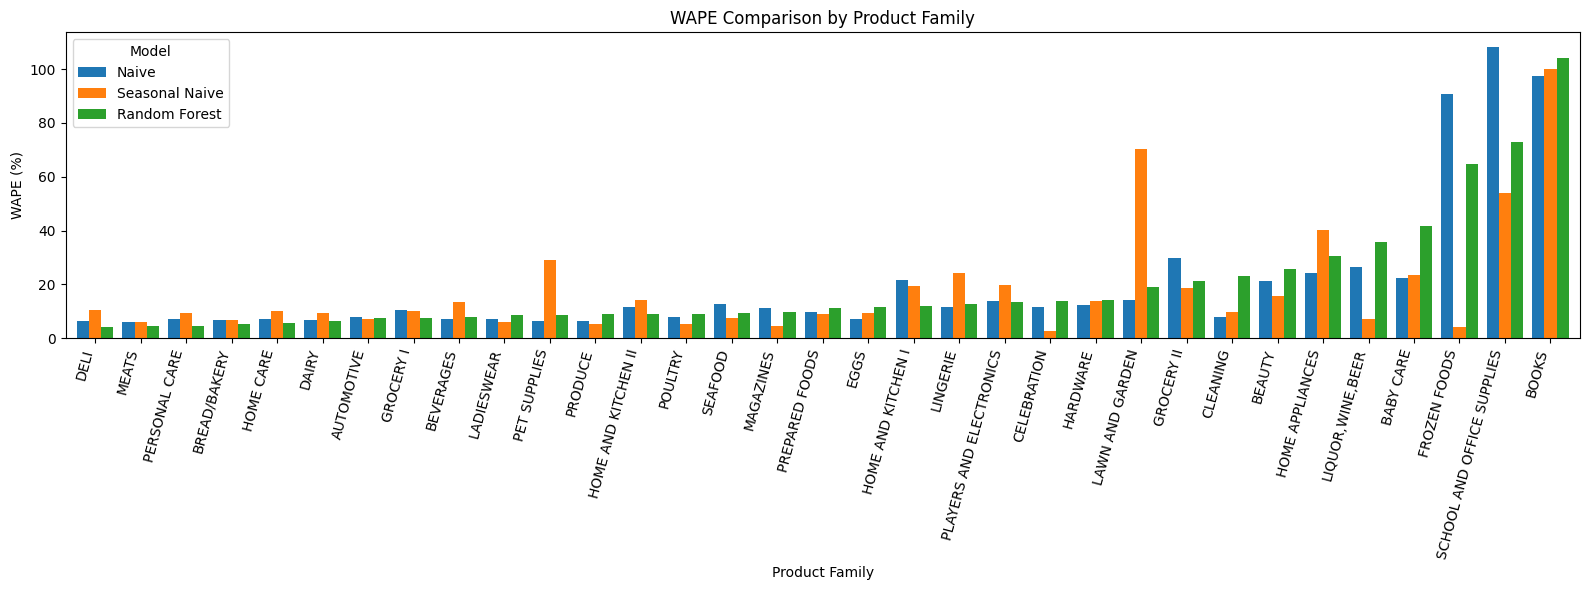

In [ ]:
import matplotlib.pyplot as plt

family_wape_plot = family_wape_comparison.sort_values(
    'Random Forest'
)

ax = family_wape_plot.plot(
    x='family',
    y=['Naive', 'Seasonal Naive', 'Random Forest'],
    kind='bar',
    figsize=(16, 6),
    width=0.8
)

ax.set_title('WAPE Comparison by Product Family')
ax.set_xlabel('Product Family')
ax.set_ylabel('WAPE (%)')
ax.legend(title='Model')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

**bold text** Interpretation

The results show that forecasting performance varies considerably across product families. No single model consistently achieves the lowest WAPE for every family.

Random Forest performs well for several product families, including DELI, MEATS, PERSONAL CARE, BREAD/BAKERY, HOME CARE, DAIRY, and GROCERY I. For these families, it achieves lower WAPE than both baseline models. This suggests that the lag features, rolling mean, and product family information help the model capture certain sales patterns.

However, simpler baseline models perform better for several other families. Seasonal Naive achieves the lowest WAPE for categories such as PRODUCE, POULTRY, MAGAZINES, and FROZEN FOODS. This indicates that historical seasonal patterns can provide useful forecasting information for these categories.

Some product families remain difficult to forecast. BOOKS has a WAPE of approximately 97% for Naive, 100% for Seasonal Naive, and 104% for Random Forest. SCHOOL AND OFFICE SUPPLIES also has relatively high errors, although Random Forest performs better than Naive for this family. These results may reflect irregular sales patterns or the relatively small scale of sales in certain categories.

Overall, the findings suggest that model performance depends on the characteristics of each product family. Random Forest is a promising candidate for some categories, but its overall performance does not consistently surpass the baseline models. Further feature evaluation is needed before selecting the final forecasting model.

## 5.12 Feature Improvement: Testing Lag 12

This experiment evaluates whether adding a 12-month lag feature improves Random Forest forecasting performance.

The `lag_12` feature represents sales from the same month in the previous year. It may help the model capture annual seasonal patterns that are not fully represented by the existing lag and rolling mean features.

Two Random Forest configurations are compared:

- **Model A:** Uses the existing baseline features without `lag_12`.
- **Model B:** Uses the same features with the additional `lag_12` feature.

Both configurations use the same five forecast origins, three-month forecasting horizon, and evaluation metrics: MAE, RMSE, and WAPE. This ensures that the effect of adding `lag_12` can be evaluated under consistent conditions.

In [ ]:
lag12_features = baseline_features + ['lag_12']

print('Baseline feature count:', len(baseline_features))
print('Features with lag_12:', len(lag12_features))

print(
    'Missing lag_12 values:',
    feature_data['lag_12'].isna().sum()
)

print(
    'Available rows for lag_12 model:',
    feature_data.dropna(subset=lag12_features).shape[0]
)

Baseline feature count: 7
Features with lag_12: 8
Missing lag_12 values: 396
Available rows for lag_12 model: 1419


### 5.12.1 Build the Random Forest Model with Lag 12

A second Random Forest pipeline is created by adding `lag_12` to the numeric feature set. The same preprocessing approach and Random Forest hyperparameters are retained to make the comparison more consistent.

Rows without sufficient historical data for `lag_12` are excluded from Model B training. The baseline model remains unchanged.

In [ ]:
numeric_features_lag12 = numeric_features + ['lag_12']

preprocessor_lag12 = ColumnTransformer(
    transformers=[
        (
            'family_encoder',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numeric_features',
            'passthrough',
            numeric_features_lag12
        )
    ]
)

rf_pipeline_lag12 = Pipeline(
    steps=[
        ('preprocessor', preprocessor_lag12),
        (
            'model',
            RandomForestRegressor(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print('Baseline features:', len(baseline_features))
print('Lag 12 model features:', len(categorical_features) + len(numeric_features_lag12))
print('Lag 12 model pipeline created successfully.')

Baseline features: 7
Lag 12 model features: 8
Lag 12 model pipeline created successfully.


### 5.12.2 Recursive Forecasting with Lag 12

The recursive forecasting function is extended to support both feature configurations. At each forecast origin, the model is trained only on observations available at that time.

For Model B, the 12-month lag is generated from the historical sales sequence. During forecasting, predictions are appended to the sequence and used when constructing future features. This prevents the model from using actual sales values from the forecast period.

In [ ]:
lag12_training_data = feature_data[
    ['month', 'date'] + lag12_features + ['sales']
].copy()

print('Lag 12 training data shape:', lag12_training_data.shape)
print('Missing lag_12:', lag12_training_data['lag_12'].isna().sum())
print(
    'Available training rows:',
    lag12_training_data.dropna(subset=lag12_features).shape[0]
)

Lag 12 training data shape: (1815, 11)
Missing lag_12: 396
Available training rows: 1419


In [ ]:
def recursive_forecast(
    training_feature_data,
    raw_sales_data,
    forecast_origin,
    horizon=3,
    use_lag12=False
):
    selected_features = (
        baseline_features + ['lag_12']
        if use_lag12
        else baseline_features
    )

    selected_numeric_features = (
        numeric_features + ['lag_12']
        if use_lag12
        else numeric_features
    )

    selected_pipeline = (
        rf_pipeline_lag12 if use_lag12 else rf_pipeline
    )

    # Restrict training data to the forecast origin
    train_history = training_feature_data.loc[
        training_feature_data['month'] <= forecast_origin
    ].dropna(subset=selected_features).copy()

    X_fit = train_history[
        categorical_features + selected_numeric_features
    ]
    y_fit = train_history['sales']

    model = clone(selected_pipeline)
    model.fit(X_fit, y_fit)

    predictions = []

    for family in sorted(raw_sales_data['family'].unique()):
        family_history = raw_sales_data.loc[
            (raw_sales_data['family'] == family)
            & (raw_sales_data['month'] <= forecast_origin)
        ].sort_values('month')

        sales_history = family_history['sales'].tolist()

        for step in range(1, horizon + 1):
            target_month = forecast_origin + step

            feature_row = {
                'family': family,
                'month_number': target_month.month,
                'time_index': (
                    (target_month.year - 2013) * 12
                    + target_month.month
                ),
                'lag_1': sales_history[-1],
                'lag_2': sales_history[-2],
                'lag_3': sales_history[-3],
                'rolling_mean_3': np.mean(sales_history[-3:])
            }

            if use_lag12:
                feature_row['lag_12'] = sales_history[-12]

            next_features = pd.DataFrame([feature_row])

            predicted_sales = float(
                model.predict(next_features)[0]
            )
            predicted_sales = max(0, predicted_sales)

            predictions.append({
                'origin': forecast_origin,
                'month': target_month,
                'family': family,
                'horizon': step,
                'predicted_sales': predicted_sales
            })

            sales_history.append(predicted_sales)

    return pd.DataFrame(predictions)

In [ ]:
print('lag12_training_data exists:', 'lag12_training_data' in globals())

if 'lag12_training_data' in globals():
    print('Columns:', lag12_training_data.columns.tolist())

lag12_training_data exists: True
Columns: ['month', 'date', 'family', 'month_number', 'time_index', 'lag_1', 'lag_2', 'lag_3', 'rolling_mean_3', 'lag_12', 'sales']


In [ ]:
rf_lag12_test = recursive_forecast(
    training_feature_data=lag12_training_data,
    raw_sales_data=modeling_data,
    forecast_origin=pd.Period('2016-12', freq='M'),
    horizon=3,
    use_lag12=True
)

print('Forecast shape:', rf_lag12_test.shape)
print('Missing predictions:', rf_lag12_test['predicted_sales'].isna().sum())

display(rf_lag12_test.head(10))

Forecast shape: (99, 5)
Missing predictions: 0


,origin,month,family,horizon,predicted_sales
0,2016-12,2017-01,AUTOMOTIVE,1,1.183788e+04
1,2016-12,2017-02,AUTOMOTIVE,2,1.239269e+04
2,2016-12,2017-03,AUTOMOTIVE,3,1.254244e+04
3,2016-12,2017-01,BABY CARE,1,5.115907e+02
4,2016-12,2017-02,BABY CARE,2,5.442878e+02
5,2016-12,2017-03,BABY CARE,3,5.695503e+02
6,2016-12,2017-01,BEAUTY,1,1.278647e+04
7,2016-12,2017-02,BEAUTY,2,1.202555e+04
8,2016-12,2017-03,BEAUTY,3,1.252605e+04
9,2016-12,2017-01,BEVERAGES,1,5.903647e+06


### 5.12.3 Rolling-Origin Evaluation for Both Models

Both Random Forest configurations are evaluated using the same five forecast origins and a three-month forecasting horizon.

Model A uses the baseline features, while Model B includes the additional `lag_12` feature. At each forecast origin, both models are trained using only the historical data available at that time.

MAE, RMSE, and WAPE are calculated for each horizon and across all horizons to determine whether the additional annual lag feature improves forecasting performance.

In [ ]:
lag12_comparison_results = []

for origin in forecast_origins:
    # Model A: baseline features
    forecast_a = recursive_forecast(
        training_feature_data=baseline_data,
        raw_sales_data=modeling_data,
        forecast_origin=origin,
        horizon=forecast_horizon,
        use_lag12=False
    )

    forecast_a = forecast_a.rename(
        columns={'predicted_sales': 'prediction_a'}
    )

    # Model B: baseline features + lag_12
    forecast_b = recursive_forecast(
        training_feature_data=lag12_training_data,
        raw_sales_data=modeling_data,
        forecast_origin=origin,
        horizon=forecast_horizon,
        use_lag12=True
    )

    forecast_b = forecast_b.rename(
        columns={'predicted_sales': 'prediction_b'}
    )

    # Merge both model forecasts
    comparison = forecast_a.merge(
        forecast_b,
        on=['origin', 'month', 'family', 'horizon'],
        how='inner'
    )

    lag12_comparison_results.append(comparison)

lag12_comparison_results = pd.concat(
    lag12_comparison_results,
    ignore_index=True
)


actual_sales = modeling_data[
    ['month', 'family', 'sales']
].rename(columns={'sales': 'actual_sales'})

lag12_comparison_results = lag12_comparison_results.merge(
    actual_sales,
    on=['month', 'family'],
    how='left'
)

print('Comparison shape:', lag12_comparison_results.shape)
print(
    'Missing actual sales:',
    lag12_comparison_results['actual_sales'].isna().sum()
)

display(lag12_comparison_results.head(10))

### 5.12.4 Compare Model Performance

The evaluation metrics for Model A and Model B are calculated using the same actual sales values across five forecast origins and three forecast horizons.

Model A uses the baseline features, while Model B adds the 12-month lag feature. Comparing their MAE, RMSE, and WAPE values helps determine whether the additional feature improves forecasting accuracy.

Lower metric values indicate better performance. The results are examined both by forecast horizon and across all evaluated predictions.

In [ ]:
lag12_metrics = []

model_predictions = {
    'Model A - Baseline': 'prediction_a',
    'Model B - Lag 12': 'prediction_b'
}

for model_name, prediction_column in model_predictions.items():
    for horizon in [1, 2, 3]:
        evaluation_data = lag12_comparison_results.loc[
            lag12_comparison_results['horizon'] == horizon
        ]

        actual = evaluation_data['actual_sales']
        predicted = evaluation_data[prediction_column]

        mae = np.mean(np.abs(actual - predicted))
        rmse = np.sqrt(np.mean((actual - predicted) ** 2))
        wape = (
            np.sum(np.abs(actual - predicted))
            / np.sum(np.abs(actual))
            * 100
        )

        lag12_metrics.append({
            'model': model_name,
            'horizon': horizon,
            'MAE': mae,
            'RMSE': rmse,
            'WAPE (%)': wape
        })

lag12_horizon_metrics = pd.DataFrame(lag12_metrics)

display(
    lag12_horizon_metrics.sort_values(
        ['horizon', 'model']
    ).round(2)
)

In [ ]:
lag12_overall_metrics = []

for model_name, prediction_column in model_predictions.items():
    actual = lag12_comparison_results['actual_sales']
    predicted = lag12_comparison_results[prediction_column]

    lag12_overall_metrics.append({
        'model': model_name,
        'MAE': np.mean(np.abs(actual - predicted)),
        'RMSE': np.sqrt(np.mean((actual - predicted) ** 2)),
        'WAPE (%)': (
            np.sum(np.abs(actual - predicted))
            / np.sum(np.abs(actual))
            * 100
        )
    })

lag12_overall_metrics = pd.DataFrame(lag12_overall_metrics)

display(lag12_overall_metrics.round(2))

**Interpretation**

The results show that adding the 12-month lag feature improves Random Forest forecasting performance across all three forecast horizons.

Overall, Model B achieves an MAE of 61,851.81, an RMSE of 172,703.29, and a WAPE of 7.86%. In comparison, Model A achieves an MAE of 74,435.41, an RMSE of 208,604.67, and a WAPE of 9.45%.

The improvement is consistent across all forecast horizons. Model B reduces WAPE from 8.39% to 7.28% at horizon 1, from 9.49% to 7.37% at horizon 2, and from 10.46% to 8.89% at horizon 3.

These results suggest that sales from the same month in the previous year provide useful information for forecasting monthly sales. The `lag_12` feature may help the model capture annual seasonal patterns that are not fully represented by shorter-term lag features.

Based on this experiment, Model B is the stronger Random Forest configuration and should be retained as a candidate for subsequent model evaluation. However, the improvement should be interpreted with consideration of the reduced training sample size caused by missing historical values for `lag_12`. Further evaluation is needed to determine whether this improvement remains consistent across product families and other forecast periods.

##5.13 Model Performance by Product Family with Lag 12

This section evaluates the improved Random Forest model with `lag_12` at the product-family level. Its performance is compared with the Naive and Seasonal Naive baselines across the same five forecast origins and three forecast horizons.

The analysis identifies which product families benefit from the Random Forest model and which are better forecast using simpler baseline methods. These results will support the selection of a suitable forecasting model for each product family.

In [ ]:
lag12_family_forecasts = []

for origin in forecast_origins:
    forecast_b = recursive_forecast(
        training_feature_data=lag12_training_data,
        raw_sales_data=modeling_data,
        forecast_origin=origin,
        horizon=forecast_horizon,
        use_lag12=True
    )

    lag12_family_forecasts.append(forecast_b)

lag12_family_forecasts = pd.concat(
    lag12_family_forecasts,
    ignore_index=True
)

print('Lag 12 forecast shape:', lag12_family_forecasts.shape)
print(
    'Forecast origins:',
    lag12_family_forecasts['origin'].nunique()
)
print(
    'Product families:',
    lag12_family_forecasts['family'].nunique()
)

display(lag12_family_forecasts.head(10))

Lag 12 forecast shape: (495, 5)
Forecast origins: 5
Product families: 33


,origin,month,family,horizon,predicted_sales
0,2016-12,2017-01,AUTOMOTIVE,1,1.183788e+04
1,2016-12,2017-02,AUTOMOTIVE,2,1.239269e+04
2,2016-12,2017-03,AUTOMOTIVE,3,1.254244e+04
3,2016-12,2017-01,BABY CARE,1,5.115907e+02
4,2016-12,2017-02,BABY CARE,2,5.442878e+02
5,2016-12,2017-03,BABY CARE,3,5.695503e+02
6,2016-12,2017-01,BEAUTY,1,1.278647e+04
7,2016-12,2017-02,BEAUTY,2,1.202555e+04
8,2016-12,2017-03,BEAUTY,3,1.252605e+04
9,2016-12,2017-01,BEVERAGES,1,5.903647e+06


### 5.13.1 Calculate Metrics by Product Family

This section evaluates the Naive, Seasonal Naive, and improved Random Forest models with `lag_12` separately for each product family.

MAE, RMSE, and WAPE are calculated using predictions from all five forecast origins and three forecast horizons. The results help identify which model performs best for each family and whether the improved Random Forest model provides better forecasts than the baseline methods.

In [ ]:
family_lag12_metrics_results = []

family_model_predictions = {
    'Naive': 'naive_prediction',
    'Seasonal Naive': 'seasonal_naive_prediction',
    'Random Forest Lag 12': 'predicted_sales'
}

for family in sorted(modeling_data['family'].unique()):
    family_actual = modeling_data.loc[
        modeling_data['family'] == family,
        ['month', 'family', 'sales']
    ]

    family_results = rolling_forecast_results.loc[
        rolling_forecast_results['family'] == family,
        ['origin', 'month', 'family', 'horizon',
         'actual_sales', 'naive_prediction',
         'seasonal_naive_prediction']
    ].merge(
        lag12_family_forecasts.loc[
            lag12_family_forecasts['family'] == family,
            ['origin', 'month', 'family', 'predicted_sales']
        ],
        on=['origin', 'month', 'family'],
        how='inner'
    )

    for model_name, prediction_column in family_model_predictions.items():
        actual = family_results['actual_sales']
        predicted = family_results[prediction_column]

        mae = np.mean(np.abs(actual - predicted))
        rmse = np.sqrt(np.mean((actual - predicted) ** 2))
        wape = (
            np.sum(np.abs(actual - predicted))
            / np.sum(np.abs(actual))
            * 100
        )

        family_lag12_metrics_results.append({
            'family': family,
            'model': model_name,
            'MAE': mae,
            'RMSE': rmse,
            'WAPE (%)': wape
        })

family_lag12_metrics = pd.DataFrame(
    family_lag12_metrics_results
)

display(
    family_lag12_metrics.sort_values(
        ['family', 'WAPE (%)']
    ).round(2)
)

print('Metrics table shape:', family_lag12_metrics.shape)

,family,model,MAE,RMSE,WAPE (%)
1,AUTOMOTIVE,Seasonal Naive,870.40,1107.48,7.08
2,AUTOMOTIVE,Random Forest Lag 12,893.51,1031.52,7.27
0,AUTOMOTIVE,Naive,973.13,1093.56,7.91
3,BABY CARE,Naive,80.53,104.25,22.50
4,BABY CARE,Seasonal Naive,84.27,109.38,23.55
...,...,...,...,...,...
95,SCHOOL AND OFFICE SUPPLIES,Random Forest Lag 12,7727.06,10912.43,72.38
93,SCHOOL AND OFFICE SUPPLIES,Naive,11558.80,15178.73,108.27
97,SEAFOOD,Seasonal Naive,2811.93,3215.98,7.58
98,SEAFOOD,Random Forest Lag 12,3151.66,3748.95,8.50


Metrics table shape: (99, 5)


### 5.13.2 Select the Best Model for Each Product Family

The evaluation metrics are reorganized to compare WAPE across the three forecasting models for each product family. The model with the lowest WAPE is identified as the best-performing candidate for that family.

This selection is based on the combined results from five forecast origins and three forecast horizons. The selected models will be treated as candidates for the final forecasting stage, subject to further validation.

In [ ]:
family_wape_comparison_lag12 = family_lag12_metrics.pivot(
    index='family',
    columns='model',
    values='WAPE (%)'
).reset_index()

model_columns = [
    'Naive',
    'Seasonal Naive',
    'Random Forest Lag 12'
]

family_wape_comparison_lag12['Best Model'] = (
    family_wape_comparison_lag12[model_columns]
    .idxmin(axis=1)
)

display(
    family_wape_comparison_lag12.sort_values(
        'Best Model'
    ).round(2)
)

print(
    'Number of product families:',
    family_wape_comparison_lag12.shape[0]
)



model,family,Naive,Random Forest Lag 12,Seasonal Naive,Best Model
1,BABY CARE,22.50,40.83,23.55,Naive
20,LAWN AND GARDEN,13.99,17.97,70.30,Naive
3,BEVERAGES,7.28,8.24,13.34,Naive
4,BOOKS,97.27,113.26,100.00,Naive
7,CLEANING,8.00,16.91,9.62,Naive
17,HOME APPLIANCES,24.23,32.09,40.18,Naive
26,PET SUPPLIES,6.53,9.41,29.01,Naive
21,LINGERIE,11.67,13.06,24.29,Naive
14,HARDWARE,12.39,12.93,13.95,Naive
16,HOME AND KITCHEN II,11.40,8.96,14.22,Random Forest Lag 12


Number of product families: 33


In [ ]:
print('\nBest model counts:')
display(
    family_wape_comparison_lag12['Best Model']
    .value_counts()
    .rename_axis('Model')
    .reset_index(name='Number of Families')
)


Best model counts:


,Model,Number of Families
0,Seasonal Naive,13
1,Random Forest Lag 12,11
2,Naive,9


**Interpretation**

The results show that the best-performing forecasting model varies across product families. Seasonal Naive achieves the lowest WAPE for 13 families, Random Forest with `lag_12` performs best for 11 families, and Naive performs best for 9 families.

Seasonal Naive is the most frequently selected model, suggesting that recurring annual sales patterns are useful for forecasting several product families. Random Forest with `lag_12` also performs well for a substantial number of families, including DELI, GROCERY I, MEATS, and PERSONAL CARE. This indicates that machine learning features can provide additional predictive value for certain categories.

Naive remains the best candidate for some families, such as BEVERAGES, CLEANING, and PET SUPPLIES. This demonstrates that recent sales levels can sometimes provide a more reliable forecast than more complex approaches.

Overall, the results support a product-family-specific model selection strategy rather than using a single forecasting model for every category. However, these selections are based on the current validation results and should be confirmed through further evaluation before final deployment.

### 5.13.3 Model Performance by Product Family and Forecast Horizon

A model that performs best overall for a product family may not be the best choice at every forecast horizon. This section compares the Naive, Seasonal Naive, and Random Forest with `lag_12` separately for each product family and forecast horizon.

The analysis helps identify whether model performance remains consistent across one-, two-, and three-month forecasts. These findings will support the final model selection strategy.

In [ ]:
family_horizon_metrics_results = []

lag12_predictions = lag12_family_forecasts.rename(
    columns={'predicted_sales': 'rf_lag12_prediction'}
)

combined_forecasts = rolling_forecast_results.merge(
    lag12_predictions[
        ['origin', 'month', 'family', 'horizon', 'rf_lag12_prediction']
    ],
    on=['origin', 'month', 'family', 'horizon'],
    how='inner'
)

model_predictions_by_horizon = {
    'Naive': 'naive_prediction',
    'Seasonal Naive': 'seasonal_naive_prediction',
    'Random Forest Lag 12': 'rf_lag12_prediction'
}

for family in sorted(combined_forecasts['family'].unique()):
    for horizon in [1, 2, 3]:
        family_horizon_data = combined_forecasts.loc[
            (combined_forecasts['family'] == family)
            & (combined_forecasts['horizon'] == horizon)
        ]

        for model_name, prediction_column in model_predictions_by_horizon.items():
            actual = family_horizon_data['actual_sales']
            predicted = family_horizon_data[prediction_column]

            wape = (
                np.sum(np.abs(actual - predicted))
                / np.sum(np.abs(actual))
                * 100
            )

            family_horizon_metrics_results.append({
                'family': family,
                'horizon': horizon,
                'model': model_name,
                'WAPE (%)': wape
            })

family_horizon_metrics = pd.DataFrame(
    family_horizon_metrics_results
)

display(
    family_horizon_metrics.sort_values(
        ['family', 'horizon', 'WAPE (%)']
    ).round(2)
)

print('Metrics table shape:', family_horizon_metrics.shape)
print('Missing actual sales:', combined_forecasts['actual_sales'].isna().sum())
print('Missing lag 12 predictions:', combined_forecasts['rf_lag12_prediction'].isna().sum())

,family,horizon,model,WAPE (%)
1,AUTOMOTIVE,1,Seasonal Naive,5.80
0,AUTOMOTIVE,1,Naive,7.71
2,AUTOMOTIVE,1,Random Forest Lag 12,8.00
4,AUTOMOTIVE,2,Seasonal Naive,7.40
5,AUTOMOTIVE,2,Random Forest Lag 12,7.97
...,...,...,...,...
293,SEAFOOD,2,Random Forest Lag 12,8.61
291,SEAFOOD,2,Naive,8.68
295,SEAFOOD,3,Seasonal Naive,8.72
296,SEAFOOD,3,Random Forest Lag 12,9.99


Metrics table shape: (297, 4)
Missing actual sales: 0
Missing lag 12 predictions: 0


### 5.13.4 Best Model by Product Family and Forecast Horizon

This section identifies the best-performing model for each product family at each forecast horizon based on WAPE. A lower WAPE indicates a smaller forecasting error relative to actual sales.

Evaluating each horizon separately helps determine whether a model performs consistently across short-term and longer-term forecasts.

In [ ]:
best_model_by_horizon = (
    family_horizon_metrics
    .sort_values('WAPE (%)')
    .groupby(['family', 'horizon'], as_index=False)
    .first()
)

display(
    best_model_by_horizon.sort_values(
        ['family', 'horizon']
    ).round(2)
)




,family,horizon,model,WAPE (%)
0,AUTOMOTIVE,1,Seasonal Naive,5.80
1,AUTOMOTIVE,2,Seasonal Naive,7.40
2,AUTOMOTIVE,3,Random Forest Lag 12,5.85
3,BABY CARE,1,Naive,10.99
4,BABY CARE,2,Naive,22.74
...,...,...,...,...
94,SCHOOL AND OFFICE SUPPLIES,2,Seasonal Naive,52.33
95,SCHOOL AND OFFICE SUPPLIES,3,Seasonal Naive,56.40
96,SEAFOOD,1,Seasonal Naive,5.94
97,SEAFOOD,2,Seasonal Naive,8.12


In [ ]:
print('Best-model table shape:', best_model_by_horizon.shape)

Best-model table shape: (99, 4)


In [ ]:
print('\nBest model counts by horizon:')
display(
    best_model_by_horizon
    .groupby(['horizon', 'model'])
    .size()
    .unstack(fill_value=0)
)


Best model counts by horizon:


model,Naive,Random Forest Lag 12,Seasonal Naive
horizon,,,
1,12,10,11
2,13,9,11
3,9,11,13


**Interpretation**

The results show that the best-performing forecasting model varies across product families and forecast horizons.

Naive performs best for the largest number of product families at horizons of one and two months, while Seasonal Naive performs best for the largest number of families at the three-month horizon. Random Forest Lag 12 remains competitive and achieves the lowest WAPE for several product families, particularly at the longer horizon.

These findings suggest that model performance depends on the sales patterns of individual product families and the forecast horizon. Therefore, selecting one model for all product families may not produce the best results.

The results support further evaluation of a family-specific model selection strategy. However, the final approach should also consider overall forecasting errors and the consistency of model performance across forecast origins.

### 5.13.5 Model Selection by Product Family

This section compares Naive, Seasonal Naive, and Random Forest Lag 12 for each product family across all five forecast origins and all three forecast horizons.

MAE, RMSE, and WAPE are used to evaluate forecasting performance. Since these metrics measure different aspects of prediction error and have different scales, their raw values are not averaged directly. Instead, each model is ranked separately for each metric within each product family, and the average rank is used to determine the preferred model.

A lower average rank indicates better overall performance across the three evaluation metrics.

In [ ]:
lag12_predictions = lag12_family_forecasts.rename(
    columns={'predicted_sales': 'rf_lag12_prediction'}
)

combined_forecasts = rolling_forecast_results.merge(
    lag12_predictions[
        ['origin', 'month', 'family', 'horizon', 'rf_lag12_prediction']
    ],
    on=['origin', 'month', 'family', 'horizon'],
    how='inner'
)

model_prediction_columns = {
    'Naive': 'naive_prediction',
    'Seasonal Naive': 'seasonal_naive_prediction',
    'Random Forest Lag 12': 'rf_lag12_prediction'
}

family_model_metrics = []

for family in sorted(combined_forecasts['family'].unique()):
    family_data = combined_forecasts.loc[
        combined_forecasts['family'] == family
    ]

    actual = family_data['actual_sales'].to_numpy()

    for model_name, prediction_column in model_prediction_columns.items():
        predicted = family_data[prediction_column].to_numpy()
        errors = actual - predicted

        mae = np.mean(np.abs(errors))
        rmse = np.sqrt(np.mean(errors ** 2))
        wape = np.sum(np.abs(errors)) / np.sum(np.abs(actual)) * 100

        family_model_metrics.append({
            'family': family,
            'model': model_name,
            'MAE': mae,
            'RMSE': rmse,
            'WAPE (%)': wape
        })

family_model_metrics = pd.DataFrame(family_model_metrics)

for metric in ['MAE', 'RMSE', 'WAPE (%)']:
    family_model_metrics[f'{metric}_rank'] = (
        family_model_metrics.groupby('family')[metric]
        .rank(method='average', ascending=True)
    )

rank_columns = ['MAE_rank', 'RMSE_rank', 'WAPE (%)_rank']

family_model_metrics['average_rank'] = (
    family_model_metrics[rank_columns].mean(axis=1)
)

family_model_metrics = family_model_metrics.sort_values(
    ['family', 'average_rank', 'WAPE (%)']
)

display(family_model_metrics.round(3))

print('Metrics table shape:', family_model_metrics.shape)
print(
    'Missing values:',
    family_model_metrics[
        ['MAE', 'RMSE', 'WAPE (%)', 'average_rank']
    ].isna().sum().sum()
)

,family,model,MAE,RMSE,WAPE (%),MAE_rank,RMSE_rank,WAPE (%)_rank,average_rank
1,AUTOMOTIVE,Seasonal Naive,870.400,1107.480,7.078,1.0,3.0,1.0,1.667
2,AUTOMOTIVE,Random Forest Lag 12,893.509,1031.525,7.266,2.0,1.0,2.0,1.667
0,AUTOMOTIVE,Naive,973.133,1093.557,7.913,3.0,2.0,3.0,2.667
3,BABY CARE,Naive,80.533,104.245,22.504,1.0,1.0,1.0,1.000
4,BABY CARE,Seasonal Naive,84.267,109.375,23.547,2.0,2.0,2.0,2.000
...,...,...,...,...,...,...,...,...,...
95,SCHOOL AND OFFICE SUPPLIES,Random Forest Lag 12,7727.056,10912.432,72.378,2.0,2.0,2.0,2.000
93,SCHOOL AND OFFICE SUPPLIES,Naive,11558.800,15178.728,108.270,3.0,3.0,3.0,3.000
97,SEAFOOD,Seasonal Naive,2811.930,3215.982,7.580,1.0,1.0,1.0,1.000
98,SEAFOOD,Random Forest Lag 12,3151.661,3748.945,8.496,2.0,2.0,2.0,2.000


Metrics table shape: (99, 9)
Missing values: 0


In [ ]:
best_model_per_family = (
    family_model_metrics
    .sort_values(['family', 'average_rank', 'WAPE (%)'])
    .groupby('family', as_index=False)
    .first()
)

display(
    best_model_per_family[
        ['family', 'model', 'MAE', 'RMSE', 'WAPE (%)', 'average_rank']
    ].round(3)
)

print('Selected families:', best_model_per_family['family'].nunique())


,family,model,MAE,RMSE,WAPE (%),average_rank
0,AUTOMOTIVE,Seasonal Naive,870.400,1107.480,7.078,1.667
1,BABY CARE,Naive,80.533,104.245,22.504,1.000
2,BEAUTY,Seasonal Naive,1313.933,1619.143,15.521,1.000
3,BEVERAGES,Naive,426214.333,568495.260,7.279,1.000
4,BOOKS,Naive,303.733,333.681,97.267,1.000
5,BREAD/BAKERY,Random Forest Lag 12,45635.639,55859.035,4.988,1.000
6,CELEBRATION,Seasonal Naive,550.133,746.038,2.462,1.000
7,CLEANING,Naive,165137.133,202433.309,7.996,1.000
8,DAIRY,Random Forest Lag 12,103085.454,132396.088,6.639,1.000
9,DELI,Random Forest Lag 12,15789.209,18646.697,3.029,1.000


Selected families: 33


In [ ]:
print('\nNumber of families selected per model:')
display(
    best_model_per_family['model'].value_counts().to_frame('family_count')
)


Number of families selected per model:


,family_count
model,
Seasonal Naive,13
Random Forest Lag 12,11
Naive,9


**Interpretation**

The model selection results show that Seasonal Naive performs best for 13 product families, Random Forest Lag 12 for 11 families, and Naive for 9 families.

Seasonal Naive is the most frequently selected model, suggesting that recurring annual sales patterns provide useful forecasting information for several product families. Random Forest Lag 12 is preferred for families where a model using historical sales features performs better, while Naive remains competitive for families that benefit from recent sales observations.

These results support the family-specific model selection strategy. Instead of applying a single forecasting method to all product families, each family is assigned the model with the best average rank across MAE, RMSE, and WAPE during rolling-origin evaluation.

The selected models are candidates based on historical validation results. Their future forecasting performance is not guaranteed and should be interpreted in the context of the evaluation period.

## 5.14 Model Stability Analysis



### 5.14.1 Performance Across Forecast Origins

This section examines whether forecasting performance remains consistent across different forecast origins. A model that performs well across multiple origins may be more reliable than a model whose performance varies substantially between evaluation periods.

MAE, RMSE, and WAPE are evaluated separately for each forecast origin, using predictions from all product families and the three forecast horizons.

In [ ]:
stability_predictions = combined_forecasts.copy()

prediction_columns = {
    'Naive': 'naive_prediction',
    'Seasonal Naive': 'seasonal_naive_prediction',
    'Random Forest Lag 12': 'rf_lag12_prediction'
}

origin_stability_results = []

for origin in sorted(stability_predictions['origin'].unique()):
    origin_data = stability_predictions.loc[
        stability_predictions['origin'] == origin
    ]

    actual = origin_data['actual_sales'].to_numpy()

    for model_name, prediction_column in prediction_columns.items():
        predicted = origin_data[prediction_column].to_numpy()
        errors = actual - predicted

        origin_stability_results.append({
            'origin': str(origin),
            'model': model_name,
            'MAE': np.mean(np.abs(errors)),
            'RMSE': np.sqrt(np.mean(errors ** 2)),
            'WAPE (%)': (
                np.sum(np.abs(errors))
                / np.sum(np.abs(actual))
                * 100
            )
        })

origin_stability_metrics = pd.DataFrame(
    origin_stability_results
)

display(
    origin_stability_metrics
    .sort_values(['origin', 'WAPE (%)'])
    .round(2)
)

print('Table shape:', origin_stability_metrics.shape)
print(
    'Number of forecast origins:',
    origin_stability_metrics['origin'].nunique()
)

,origin,model,MAE,RMSE,WAPE (%)
1,2016-12,Seasonal Naive,75185.61,217182.91,9.76
2,2016-12,Random Forest Lag 12,97302.29,248790.94,12.63
0,2016-12,Naive,137156.84,427605.92,17.80
3,2017-01,Naive,54024.75,156774.98,7.05
5,2017-01,Random Forest Lag 12,62923.96,166495.40,8.21
4,2017-01,Seasonal Naive,66006.19,195569.09,8.62
8,2017-02,Random Forest Lag 12,54671.60,160158.40,6.81
7,2017-02,Seasonal Naive,73978.82,210014.51,9.21
6,2017-02,Naive,100231.62,269935.16,12.48
9,2017-03,Naive,30999.25,74370.04,3.91


Table shape: (15, 5)
Number of forecast origins: 5


**Interpretation**

The results show that forecasting performance varies across forecast origins. Naive achieves the lowest WAPE in three of the five origins, while Seasonal Naive performs best in December 2016 and Random Forest Lag 12 performs best in February 2017.

The WAPE values also vary across origins, indicating that forecasting accuracy depends partly on the evaluation period. Therefore, selecting a model based only on its overall performance may not fully capture its behavior across different periods.

These findings support further stability analysis at the forecast-horizon and product-family levels before finalizing the model selection strategy.

### 5.14.2 Performance Across Forecast Horizons

This section evaluates model performance separately for each forecast horizon across all five forecast origins and all product families. The objective is to determine whether each model maintains consistent forecasting performance as the prediction horizon increases from one to three months.

In [ ]:
horizon_stability_results = []

for horizon in [1, 2, 3]:
    horizon_data = combined_forecasts.loc[
        combined_forecasts['horizon'] == horizon
    ]

    actual = horizon_data['actual_sales'].to_numpy()

    for model_name, prediction_column in prediction_columns.items():
        predicted = horizon_data[prediction_column].to_numpy()
        errors = actual - predicted

        horizon_stability_results.append({
            'horizon': horizon,
            'model': model_name,
            'MAE': np.mean(np.abs(errors)),
            'RMSE': np.sqrt(np.mean(errors ** 2)),
            'WAPE (%)': (
                np.sum(np.abs(errors))
                / np.sum(np.abs(actual))
                * 100
            )
        })

horizon_stability_metrics = pd.DataFrame(
    horizon_stability_results
)

display(
    horizon_stability_metrics
    .sort_values(['horizon', 'WAPE (%)'])
    .round(2)
)

print('Table shape:', horizon_stability_metrics.shape)

,horizon,model,MAE,RMSE,WAPE (%)
2,1,Random Forest Lag 12,56964.84,157775.23,7.28
1,1,Seasonal Naive,67823.81,192461.82,8.67
0,1,Naive,76339.92,246361.81,9.76
5,2,Random Forest Lag 12,57383.63,150489.02,7.37
3,2,Naive,71767.30,269047.55,9.22
4,2,Seasonal Naive,74597.60,216497.60,9.58
6,3,Naive,66418.12,204997.43,8.29
8,3,Random Forest Lag 12,71206.97,204790.89,8.89
7,3,Seasonal Naive,87912.20,250991.56,10.97


Table shape: (9, 5)


**Interpretation**

The results show that Random Forest Lag 12 achieves the lowest WAPE at the one-month and two-month forecast horizons, with values of 7.28% and 7.37%, respectively. At the three-month horizon, Naive achieves the lowest WAPE at 8.29%.

Random Forest Lag 12 remains competitive across all three horizons, although its WAPE increases at the longest horizon. Seasonal Naive shows a larger increase in WAPE as the forecast horizon extends to three months.

These findings indicate that forecasting performance varies by horizon. Therefore, model selection should consider performance across multiple horizons rather than relying on a single forecast horizon.

### 5.14.3 Model Selection Consistency by Product Family

This section evaluates how consistently each forecasting model performs best for individual product families across different forecast origins. The analysis compares the selected model from the overall validation results with the model achieving the lowest WAPE at each forecast origin.

This comparison helps identify product families for which model performance is consistent and those for which the preferred model changes across evaluation periods.

In [ ]:
family_origin_results = []

for (family, origin), group in combined_forecasts.groupby(
    ['family', 'origin']
):
    actual = group['actual_sales'].to_numpy()

    for model_name, prediction_column in prediction_columns.items():
        predicted = group[prediction_column].to_numpy()

        wape = (
            np.sum(np.abs(actual - predicted))
            / np.sum(np.abs(actual))
            * 100
        )

        family_origin_results.append({
            'family': family,
            'origin': str(origin),
            'model': model_name,
            'WAPE (%)': wape
        })

family_origin_metrics = pd.DataFrame(family_origin_results)

best_model_by_origin = (
    family_origin_metrics
    .sort_values(['family', 'origin', 'WAPE (%)'])
    .groupby(['family', 'origin'], as_index=False)
    .first()
)

# Compare origin-level winners with the overall selected model
selected_model_lookup = best_model_per_family[
    ['family', 'model']
].rename(columns={'model': 'selected_model'})

consistency_results = best_model_by_origin.merge(
    selected_model_lookup,
    on='family',
    how='left'
)

consistency_results['matches_selected_model'] = (
    consistency_results['model']
    == consistency_results['selected_model']
)

display(
    consistency_results.sort_values(
        ['family', 'origin']
    ).round(2)
)

print('Comparison table shape:', consistency_results.shape)
print(
    'Matching selections:',
    consistency_results['matches_selected_model'].sum(),
    'out of',
    len(consistency_results)
)

,family,origin,model,WAPE (%),selected_model,matches_selected_model
0,AUTOMOTIVE,2016-12,Random Forest Lag 12,3.94,Seasonal Naive,False
1,AUTOMOTIVE,2017-01,Seasonal Naive,6.66,Seasonal Naive,True
2,AUTOMOTIVE,2017-02,Naive,5.85,Seasonal Naive,False
3,AUTOMOTIVE,2017-03,Random Forest Lag 12,4.21,Seasonal Naive,False
4,AUTOMOTIVE,2017-04,Seasonal Naive,7.48,Seasonal Naive,True
...,...,...,...,...,...,...
160,SEAFOOD,2016-12,Random Forest Lag 12,5.83,Seasonal Naive,False
161,SEAFOOD,2017-01,Seasonal Naive,8.07,Seasonal Naive,True
162,SEAFOOD,2017-02,Seasonal Naive,5.25,Seasonal Naive,True
163,SEAFOOD,2017-03,Seasonal Naive,8.36,Seasonal Naive,True


Comparison table shape: (165, 6)
Matching selections: 97 out of 165


### 5.14.4 Summary of Model Selection Consistency

This section summarizes how often the selected model achieves the lowest WAPE across the five forecast origins for each product family. The results help distinguish product families with consistent model performance from those where the preferred model changes frequently.

In [ ]:
family_consistency_summary = (
    consistency_results
    .groupby(['family', 'selected_model'], as_index=False)
    .agg(
        matching_origins=('matches_selected_model', 'sum'),
        total_origins=('origin', 'count')
    )
)

family_consistency_summary['consistency (%)'] = (
    family_consistency_summary['matching_origins']
    / family_consistency_summary['total_origins']
    * 100
)

family_consistency_summary = family_consistency_summary.sort_values(
    ['consistency (%)', 'family'],
    ascending=[True, True]
)

display(family_consistency_summary.round(2))

print('\nConsistency distribution:')
display(
    family_consistency_summary['matching_origins']
    .value_counts()
    .sort_index()
    .rename_axis('matching_origins_out_of_5')
    .to_frame('family_count')
)

print(
    '\nAverage consistency:',
    round(family_consistency_summary['consistency (%)'].mean(), 2),
    '%'
)

,family,selected_model,matching_origins,total_origins,consistency (%)
4,BOOKS,Naive,1,5,20.0
19,LADIESWEAR,Seasonal Naive,1,5,20.0
27,PLAYERS AND ELECTRONICS,Random Forest Lag 12,1,5,20.0
0,AUTOMOTIVE,Seasonal Naive,2,5,40.0
1,BABY CARE,Naive,2,5,40.0
8,DAIRY,Random Forest Lag 12,2,5,40.0
13,GROCERY II,Seasonal Naive,2,5,40.0
14,HARDWARE,Naive,2,5,40.0
20,LAWN AND GARDEN,Naive,2,5,40.0
22,"LIQUOR,WINE,BEER",Seasonal Naive,2,5,40.0



Consistency distribution:


,family_count
matching_origins_out_of_5,
1,3
2,8
3,12
4,8
5,2



Average consistency: 58.79 %


### 5.14.5 WAPE Gap Between Selected and Best Models

This section measures the difference between the WAPE of the selected model and the lowest WAPE achieved at each forecast origin for each product family.

A small WAPE gap indicates that the selected model performs similarly to the best-performing model, even when it does not achieve the lowest WAPE. A larger gap indicates a more substantial performance difference and may suggest that the model selection should be reviewed.

In [ ]:
# Calculate the WAPE gap between the selected model and
# the best-performing model at each family-origin combination

selected_wape = family_origin_metrics.merge(
    selected_model_lookup,
    on='family',
    how='left'
)

selected_wape = selected_wape.loc[
    selected_wape['model'] == selected_wape['selected_model']
].copy()

best_wape_by_origin = (
    family_origin_metrics
    .groupby(['family', 'origin'], as_index=False)['WAPE (%)']
    .min()
    .rename(columns={'WAPE (%)': 'best_wape'})
)

wape_gap_results = selected_wape.merge(
    best_wape_by_origin,
    on=['family', 'origin'],
    how='inner'
)

wape_gap_results['wape_gap'] = (
    wape_gap_results['WAPE (%)']
    - wape_gap_results['best_wape']
)

print('Selected model WAPE gap summary:')
display(
    wape_gap_results['wape_gap']
    .describe()
    .round(3)
    .to_frame('WAPE gap (percentage points)')
)

print('\nLargest WAPE gaps:')
display(
    wape_gap_results
    .sort_values('wape_gap', ascending=False)
    [['family', 'origin', 'selected_model', 'WAPE (%)', 'best_wape', 'wape_gap']]
    .head(10)
    .round(3)
)

print(
    '\nRows checked:',
    len(wape_gap_results)
)


Selected model WAPE gap summary:


,WAPE gap (percentage points)
count,165.000
mean,2.855
std,11.613
min,0.000
25%,0.000
50%,0.000
75%,1.669
max,101.277



Largest WAPE gaps:


,family,origin,selected_model,WAPE (%),best_wape,wape_gap
23,BOOKS,2017-03,Naive,201.277,100.000,101.277
24,BOOKS,2017-04,Naive,200.000,100.000,100.000
20,BOOKS,2016-12,Naive,71.643,36.100,35.543
85,HOME APPLIANCES,2016-12,Naive,48.126,27.937,20.189
21,BOOKS,2017-01,Naive,81.548,65.175,16.374
6,BABY CARE,2017-01,Naive,23.963,7.621,16.342
72,HARDWARE,2017-02,Naive,23.691,11.993,11.698
44,DAIRY,2017-04,Random Forest Lag 12,12.742,3.524,9.218
69,GROCERY II,2017-04,Seasonal Naive,37.781,28.838,8.942
113,"LIQUOR,WINE,BEER",2017-03,Seasonal Naive,10.342,1.710,8.632



Rows checked: 165


### 5.14.6 Investigating Large WAPE Gaps

This section investigates product families with unusually large WAPE gaps between the selected model and the best-performing model. The analysis focuses on actual sales volumes and absolute prediction errors to determine whether large percentage errors are associated with low sales volumes or substantial forecasting errors.

In [ ]:
# Inspect BOOKS predictions across forecast origins

books_data = combined_forecasts.loc[
    combined_forecasts['family'] == 'BOOKS'
].copy()

books_diagnostic_results = []

for origin in sorted(books_data['origin'].unique()):
    origin_data = books_data.loc[
        books_data['origin'] == origin
    ]

    actual = origin_data['actual_sales'].to_numpy()

    for model_name, prediction_column in prediction_columns.items():
        predicted = origin_data[prediction_column].to_numpy()

        books_diagnostic_results.append({
            'origin': str(origin),
            'model': model_name,
            'total_actual_sales': np.sum(actual),
            'total_predicted_sales': np.sum(predicted),
            'absolute_error': np.sum(np.abs(actual - predicted)),
            'WAPE (%)': (
                np.sum(np.abs(actual - predicted))
                / np.sum(np.abs(actual))
                * 100
            )
        })

books_diagnostic = pd.DataFrame(books_diagnostic_results)

display(
    books_diagnostic
    .sort_values(['origin', 'WAPE (%)'])
    .round(3)
)

,origin,model,total_actual_sales,total_predicted_sales,absolute_error,WAPE (%)
2,2016-12,Random Forest Lag 12,1795.0,2442.997,647.997,36.100
0,2016-12,Naive,1795.0,3081.000,1286.000,71.643
1,2016-12,Seasonal Naive,1795.0,0.000,1795.000,100.000
5,2017-01,Random Forest Lag 12,1279.0,2112.583,833.583,65.175
3,2017-01,Naive,1279.0,2322.000,1043.000,81.548
4,2017-01,Seasonal Naive,1279.0,0.000,1279.000,100.000
6,2017-02,Naive,882.0,1647.000,765.000,86.735
7,2017-02,Seasonal Naive,882.0,0.000,882.000,100.000
8,2017-02,Random Forest Lag 12,882.0,2043.230,1161.230,131.659
10,2017-03,Seasonal Naive,470.0,0.000,470.000,100.000


**Historical Sales Pattern for BOOKS**

The validation results indicate that all three forecasting models struggle to capture the declining sales pattern of the BOOKS product family. This section examines historical monthly sales to determine whether the decline is visible in the training data and whether it may explain the large forecasting errors.

In [ ]:
books_history = modeling_data.loc[
    modeling_data['family'] == 'BOOKS',
    ['month', 'sales']
].sort_values('month').copy()

books_history['month'] = books_history['month'].astype(str)

display(
    books_history.tail(24).reset_index(drop=True)
)

print('Number of monthly observations:', len(books_history))
print('Latest 12-month average sales:',
      books_history.tail(12)['sales'].mean())
print('Previous 12-month average sales:',
      books_history.tail(24).head(12)['sales'].mean())

,month,sales
0,2015-08,0.0
1,2015-09,0.0
2,2015-10,0.0
3,2015-11,0.0
4,2015-12,0.0
5,2016-01,0.0
6,2016-02,0.0
7,2016-03,0.0
8,2016-04,0.0
9,2016-05,0.0


Number of monthly observations: 55
Latest 12-month average sales: 535.8333333333334
Previous 12-month average sales: 0.0


In [ ]:
books_daily = (
    pd.read_csv(
        '/content/drive/MyDrive/retail-sales-forecasting/data/raw/train.csv',
        parse_dates=['date']
    )
    .loc[lambda df: df['family'] == 'BOOKS']
    .groupby('date', as_index=False)['sales']
    .sum()
)

books_daily['month'] = books_daily['date'].dt.to_period('M')

display(
    books_daily.loc[
        (books_daily['date'] >= '2016-08-01')
        & (books_daily['date'] <= '2016-11-30')
    ].groupby('month')['sales']
    .agg(['sum', 'count', 'mean', 'max'])
    .reset_index()
)

,month,sum,count,mean,max
0,2016-08,0.0,31,0.000000,0.0
1,2016-09,0.0,30,0.000000,0.0
2,2016-10,1783.0,31,57.516129,127.0
3,2016-11,1309.0,30,43.633333,92.0


In [ ]:
display(
    books_daily.loc[
        (books_daily['date'] >= '2015-08-01')
        & (books_daily['date'] <= '2015-11-30')
    ]
    .groupby('month')['sales']
    .agg(['sum', 'count', 'mean', 'max'])
    .reset_index()
)

,month,sum,count,mean,max
0,2015-08,0.0,31,0.0,0.0
1,2015-09,0.0,30,0.0,0.0
2,2015-10,0.0,31,0.0,0.0
3,2015-11,0.0,30,0.0,0.0


### 5.14.7 Stability Analysis Summary

The stability analysis shows that forecasting performance varies across forecast origins, forecast horizons, and product families. Random Forest Lag 12 achieves the lowest overall WAPE at the one-month and two-month horizons, while Naive performs best at the three-month horizon.

The family-level analysis shows that the selected model achieves the lowest WAPE in 97 out of 165 family-origin comparisons. However, the size of the WAPE gap varies, and some product families exhibit substantial forecasting errors due to changes in their historical sales patterns.

Based on these findings, the family-specific model selection strategy is retained for final forecasting. The selected model for each family is determined from the combined validation results using MAE, RMSE, and WAPE rankings. The stability analysis is used to document model behavior and limitations rather than to change the selected models retrospectively.

The final forecasts should therefore be interpreted as estimates based on historical sales patterns, not guaranteed future outcomes.

## 5.15 Saving Model Selection Results

The selected forecasting model for each product family is saved for use in the final forecasting notebook. This ensures that the final forecasts use the model selection results obtained during validation.

In [ ]:
from pathlib import Path

output_dir = Path(
    '/content/drive/MyDrive/retail-sales-forecasting/data/processed'
)

output_dir.mkdir(parents=True, exist_ok=True)

# Save the selected model for each product family
best_model_per_family.to_csv(
    output_dir / 'selected_models_per_family.csv',
    index=False
)

# Save detailed validation metrics
family_model_metrics.to_csv(
    output_dir / 'family_model_validation_metrics.csv',
    index=False
)

# Save stability analysis results
origin_stability_metrics.to_csv(
    output_dir / 'model_stability_by_origin.csv',
    index=False
)

horizon_stability_metrics.to_csv(
    output_dir / 'model_stability_by_horizon.csv',
    index=False
)

print('Saved files:')
for file_path in sorted(output_dir.glob('*.csv')):
    print(file_path.name)

Saved files:
family_model_validation_metrics.csv
model_stability_by_horizon.csv
model_stability_by_origin.csv
monthly_sales.csv
selected_models_per_family.csv
